### importing the librabries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# Load the dataset
df = pd.read_csv("Bengaluru_House_Data.csv")

#### Getting information about the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [8]:
# Summary statistics
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [9]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [10]:
df.shape

(13320, 9)

In [11]:
# Count of missing values
print("Missing Values (Before Cleaning):\n")
print(df.isnull().sum())

Missing Values (Before Cleaning):

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64


### Preprocess size and total_sqft

In [12]:

df['bhk'] = df['size'].apply(lambda x: str(x).split(' ')[0] if pd.notnull(x) else None)
df['bhk'] = pd.to_numeric(df['bhk'], errors='coerce')

def convert_sqft(x):
    try:
        if '-' in x:
            tokens = x.split('-')
            return (float(tokens[0]) + float(tokens[1])) / 2
        return float(x)
    except:
        return None

df['total_sqft'] = df['total_sqft'].apply(convert_sqft)
df = df.dropna(subset=['total_sqft', 'bath', 'bhk'])
df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']

### Handling the Missing Value

In [13]:


# Drop rows where 'location', 'size', 'bhk', or 'total_sqft' is missing
df.dropna(subset=['location', 'size', 'bhk', 'total_sqft'], inplace=True)

# Drop 'society' column due to high % of missing values
df.drop(columns=['society'], inplace=True)

# Fill missing 'bath' values with median of that bhk group
df['bath'] = df.groupby('bhk')['bath'].transform(lambda x: x.fillna(x.median()))

# Fill missing 'balcony' values with overall median
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

print("\nMissing Values (After Cleaning):\n")
print(df.isnull().sum())


Missing Values (After Cleaning):

area_type         0
availability      0
location          0
size              0
total_sqft        0
bath              0
balcony           0
price             0
bhk               0
price_per_sqft    0
dtype: int64


### Removing the outliers

In [14]:
# ------------------------
df = df[df['price'] < 200]
df = df[df['total_sqft'] / df['bhk'] >= 300]
df['price_per_sqft'] = (df['price'] * 100000) / df['total_sqft']
mean_pps = df['price_per_sqft'].mean()
std_pps = df['price_per_sqft'].std()
df = df[(df['price_per_sqft'] > (mean_pps - 2 * std_pps)) & 
        (df['price_per_sqft'] < (mean_pps + 2 * std_pps))]
df = df[df['bath'] < df['bhk'] + 2]

In [15]:
# Value counts
area_type_counts = df['area_type'].value_counts()
availability_counts = df['availability'].value_counts()
top_locations = df['location'].value_counts().head(10)

# Summary statistics
summary = df.describe()

# Count of missing values
missing_values = df.isnull().sum()

print("\n----- Missing Values -----")
print(missing_values)
print("\n----- Area Type Counts -----")
print(area_type_counts)
print("\n----- Availability Status -----")
print(availability_counts)
print("\n----- Top 10 Locations by Listings -----")
print(top_locations)


----- Missing Values -----
area_type         0
availability      0
location          0
size              0
total_sqft        0
bath              0
balcony           0
price             0
bhk               0
price_per_sqft    0
dtype: int64

----- Area Type Counts -----
area_type
Super built-up  Area    7925
Built-up  Area          1963
Plot  Area               590
Carpet  Area              72
Name: count, dtype: int64

----- Availability Status -----
availability
Ready To Move    8161
18-Dec            266
18-May            256
18-Apr            234
18-Aug            188
                 ... 
15-Oct              1
16-Sep              1
20-May              1
14-Nov              1
14-Jul              1
Name: count, Length: 78, dtype: int64

----- Top 10 Locations by Listings -----
location
Whitefield               435
Sarjapur  Road           329
Electronic City          287
Kanakpura Road           258
Thanisandra              226
Yelahanka                190
Uttarahalli              1

### Data visualization

#### Distribution of Area

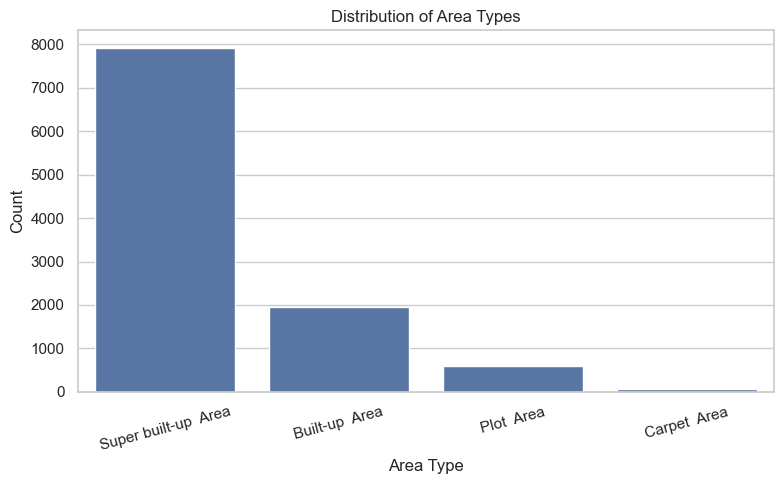

In [16]:
sns.set(style="whitegrid")

# ----- Plot 1: Area Type Distribution -----
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='area_type', order=df['area_type'].value_counts().index)
plt.title('Distribution of Area Types')
plt.xlabel('Area Type')
plt.ylabel('Count')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Distribution of BHKs 

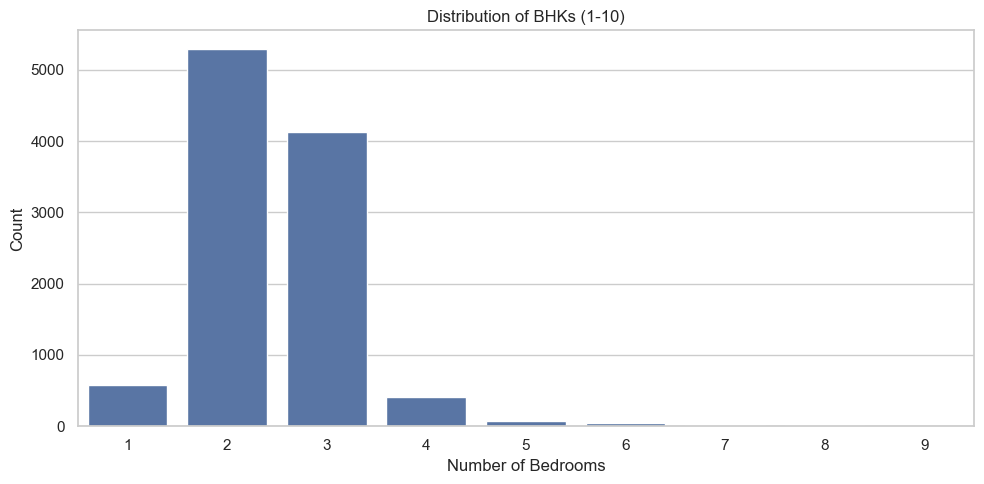

In [17]:
plt.figure(figsize=(10, 5))
# Convert BHK values to integers for cleaner x-axis
sns.countplot(x=df[df['bhk'] <= 10]['bhk'].astype(int), data=df[df['bhk'] <= 10])
plt.title('Distribution of BHKs (1-10)')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### Distribuition of House Prices

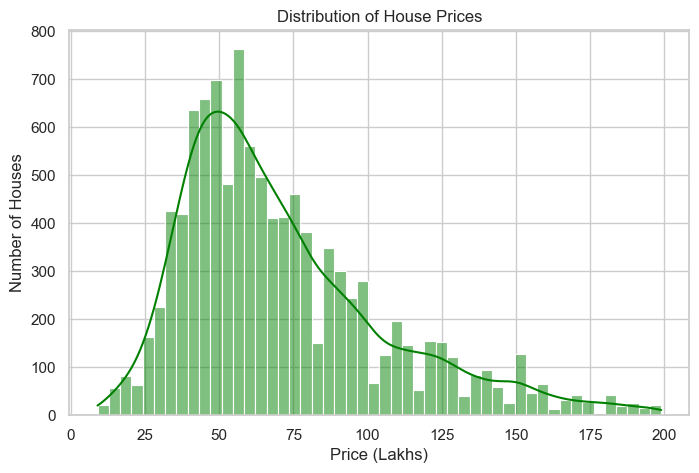

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['price'], bins=50, kde=True, color='green')
plt.title('Distribution of House Prices')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Number of Houses')
plt.show()

### Top 10 locations

C:\Users\Victus\AppData\Local\Temp\ipykernel_24988\2263524685.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.values, y=top_locations.index, palette='coolwarm')


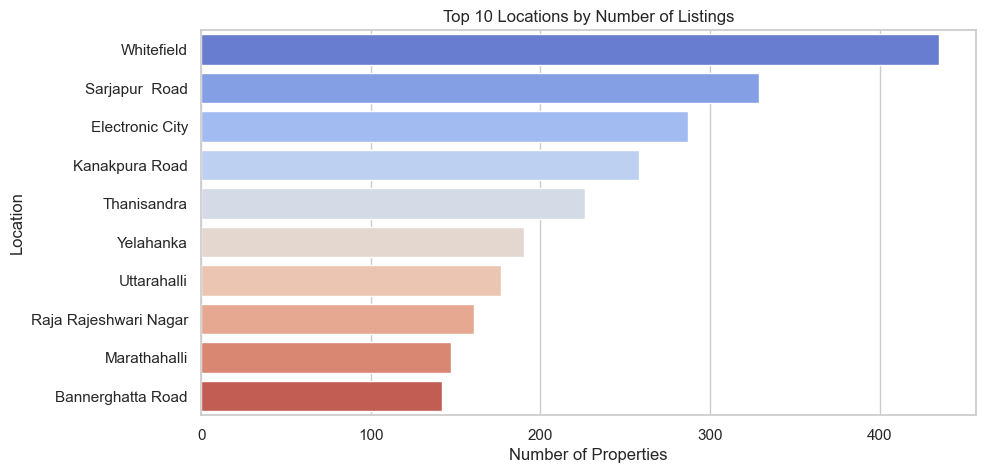

In [19]:
plt.figure(figsize=(10,5))
top_locations = df['location'].value_counts().head(10)
sns.barplot(x=top_locations.values, y=top_locations.index, palette='coolwarm')
plt.title("Top 10 Locations by Number of Listings")
plt.xlabel("Number of Properties")
plt.ylabel("Location")
plt.show()

#### Understanding the most relevant features  in my model

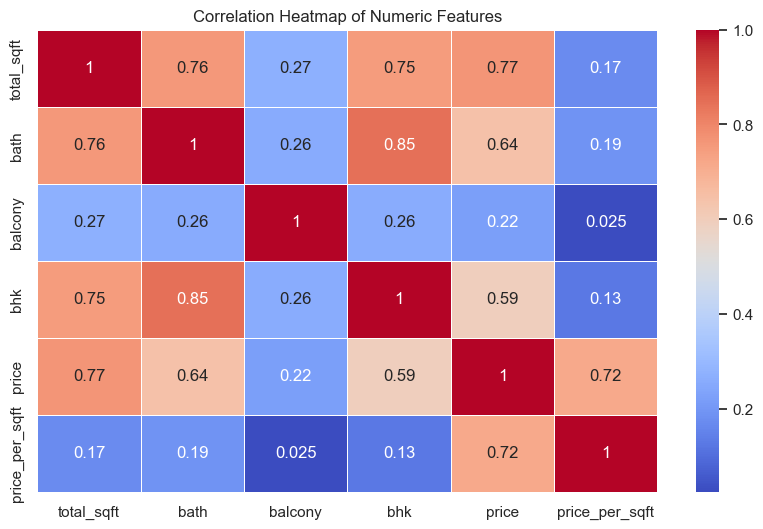

In [20]:

features = ['total_sqft', 'bath', 'balcony', 'bhk', 'price', 'price_per_sqft']
corr_matrix = df[features].corr()

# Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


### Implement Linear Regression

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [22]:
# Reduce locations with low counts
location_counts = df['location'].value_counts()
locations_to_keep = location_counts[location_counts > 10].index
df['location'] = df['location'].apply(lambda x: x if x in locations_to_keep else 'Other')

In [23]:
# One-hot encoding
df = pd.get_dummies(df, columns=['location', 'area_type'], drop_first=True)

In [24]:
# Drop unnecessary columns
df.drop(columns=['availability', 'size'], inplace=True)
# Feature-Target split
# ------------------------
X = df.drop('price', axis=1)
y = df['price']

In [25]:
# Train-test split
# ------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------
# Feature Scaling
# ------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [26]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

 Model Evaluation:
R² Score      : 0.9424233004590793
MAE           : 4.614591940735604
RMSE          : 8.44909998427589


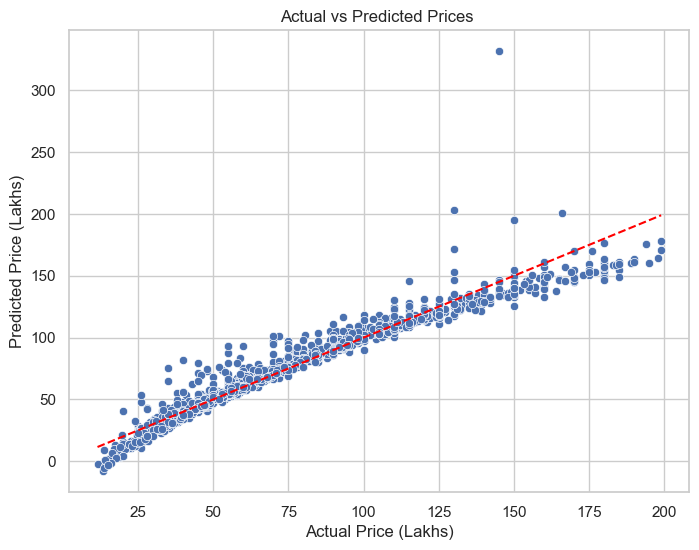

In [27]:
y_pred = model.predict(X_test_scaled)

print(" Model Evaluation:")
print("R² Score      :", r2_score(y_test, y_pred))
print("MAE           :", mean_absolute_error(y_test, y_pred))
print("RMSE          :", np.sqrt(mean_squared_error(y_test, y_pred)))

# Plot: Actual vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Diagonal line
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()


### implementing the model using DecisionTreeRegressor

Decision Tree R2 Score: 0.995915822798102
RMSE: 2.250294479182742


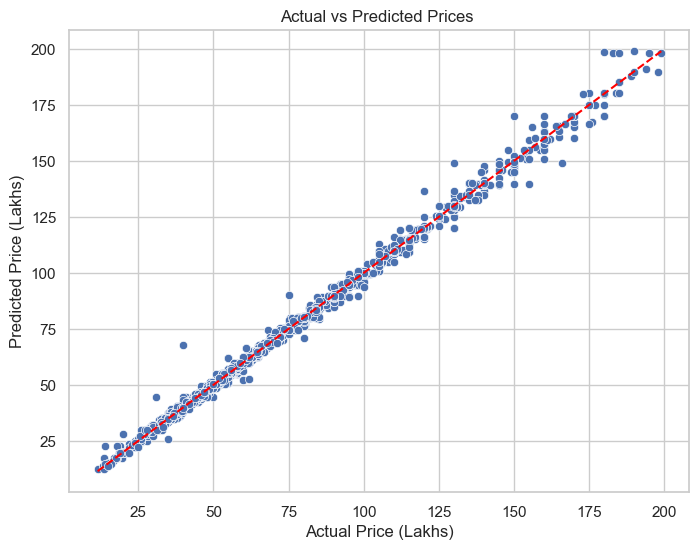

In [28]:
from sklearn.tree import DecisionTreeRegressor
##Train Decision Tree Regressor
model = DecisionTreeRegressor(max_depth=10, random_state=42)
model.fit(X_train, y_train)

##Predict and evaluate
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print("Decision Tree R2 Score:", r2)
print("RMSE:", rmse)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Diagonal line
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()


### implementing the model using Random Forest Regressor

R2 Score: 0.9989153704376077
RMSE: 1.1596522767194941


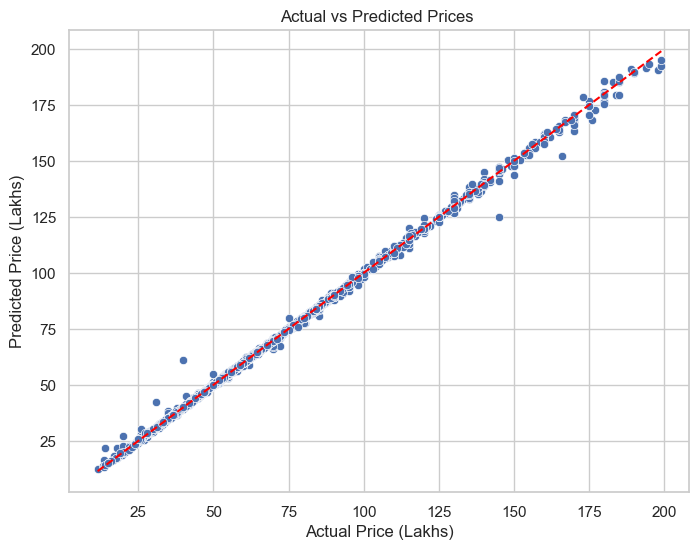

In [ ]:
# Train Random Forest Regressor
model = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
model.fit(X_train, y_train)

# Predict and Evaluate
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print("R2 Score:", r2)
print("RMSE:", rmse)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()



#### Optimizing the model using hyper parameter tuning in RandomForestRegressor

In [52]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters for Random Forest: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
R² Score : 0.9987268475743163
 MAE: 0.5983100861818921
 RMSE: 1.2563980892304596


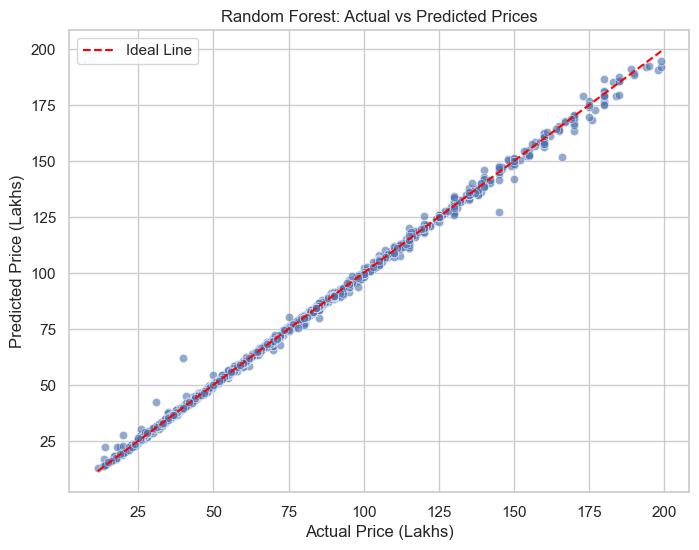

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
# Define the Random Forest model
rf = RandomForestRegressor(random_state=42)

# Smaller parameter grid for faster search
param_grid_rf = {
    'n_estimators': [100, 200],  # Removed 300 to reduce time
    'max_depth': [5, 10],        # Fewer depth options
    'min_samples_split': [2, 5]  # Removed 10 for speed
}

# Setup GridSearchCV with fewer CV folds
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=3,  # Reduced from 5 to 3
    scoring='neg_mean_squared_error',
    n_jobs=-1,  # Use all CPU cores
    verbose=1
)

# Fit GridSearchCV to the training data
grid_search_rf.fit(X_train, y_train)

# Best Random Forest model and parameters
best_rf = grid_search_rf.best_estimator_
print("Best Parameters for Random Forest:", grid_search_rf.best_params_)

# Evaluate Random Forest on test set
y_pred_rf = best_rf.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
print("R² Score :",r2_rf)
print(f" MAE: {mae_rf}\n RMSE: {rmse_rf}")

# Plot Actual vs Predicted (Random Forest)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', label='Ideal Line')
plt.title("Random Forest: Actual vs Predicted Prices")
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.legend()
plt.show()

#### Optimizing the model using hyper parameter tuning in DecisionTreeRegressor

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters for Decision Tree: {'max_depth': 8, 'min_samples_split': 2}
R² Score : 0.9987268475743163
 MAE: 0.5983100861818921
 RMSE: 1.2563980892304596


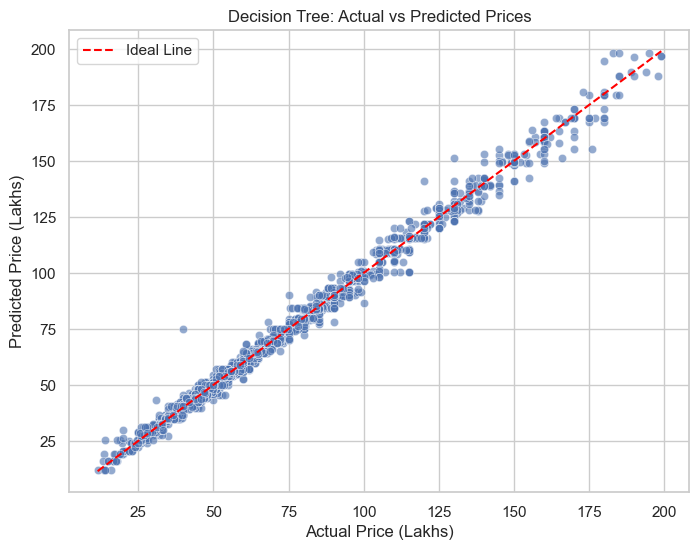

In [35]:
from sklearn.tree import DecisionTreeRegressor
# Define the Decision Tree model
dt = DecisionTreeRegressor(random_state=42)

# Smaller parameter grid for faster tuning
param_grid_dt = {
    'max_depth': [5, 8],  # Fewer options
    'min_samples_split': [2, 5]  # Fewer options
}

# Setup GridSearchCV with fewer CV folds
grid_search_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=3,  # Reduced from 5 to 3
    scoring='neg_mean_squared_error',
    n_jobs=-1,  # Use all CPU cores
    verbose=1   # Reduced verbosity
)

# Fit GridSearchCV to training data
grid_search_dt.fit(X_train, y_train)

# Best Decision Tree model and parameters
best_dt = grid_search_dt.best_estimator_
print("Best Parameters for Decision Tree:", grid_search_dt.best_params_)

# Evaluate Decision Tree on test set
y_pred_dt = best_dt.predict(X_test)
r2_dt = r2_score(y_test, y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
print("R² Score :",r2_rf)
print(f" MAE: {mae_rf}\n RMSE: {rmse_rf}")

# Plot Actual vs Predicted (Decision Tree)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred_dt, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', label='Ideal Line')
plt.title("Decision Tree: Actual vs Predicted Prices")
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.legend()
plt.show()

### Comparing the model performance


 Model Comparison:

               Model  R2 Score    MAE   RMSE
2      Random Forest     0.999  0.450  1.195
1      Decision Tree     0.996  1.225  2.250
0  Linear Regression     0.942  4.615  8.449


C:\Users\Victus\AppData\Local\Temp\ipykernel_24988\3689763363.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="R2 Score", y="Model", data=comparison_df, palette="viridis")


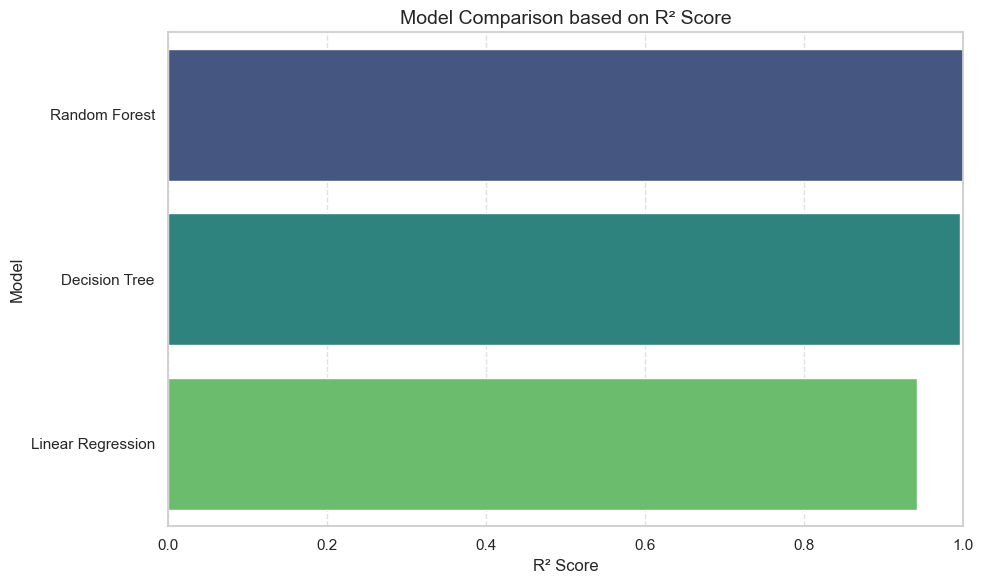

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Try to import XGBoost if available
try:
    from xgboost import XGBRegressor
    xgb_installed = True
except ImportError:
    xgb_installed = False

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

if xgb_installed:
    models["XGBoost"] = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)

# Train and evaluate
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model": name,
        "R2 Score": round(r2, 3),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

# Display results as DataFrame
comparison_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
print("\n Model Comparison:\n")
print(comparison_df)

plt.figure(figsize=(10, 6))
sns.barplot(x="R2 Score", y="Model", data=comparison_df, palette="viridis")

plt.title("Model Comparison based on R² Score", fontsize=14)
plt.xlabel("R² Score", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.xlim(0, 1)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [37]:
import joblib
# Save model and scaler
joblib.dump(model, "model.joblib")


['model.joblib']

In [38]:
joblib.dump(scaler, "scaler.joblib")

['scaler.joblib']

In [39]:
# Save feature names for the web app
feature_names = X.columns.tolist()
joblib.dump(feature_names, "feature_names.joblib")

['feature_names.joblib']